In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

==== LOADING DATA ====

In [2]:
# Connect to SQL Server using Windows Authentication.
engine = create_engine(
    "mssql+pyodbc://Desktop-84\\SQLEXPRESS/ECommerce"
    "?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
)

# Load session funnel data from SQL Server into a DataFrame.
df = pd.read_sql("SELECT * FROM store.session_funnel", con=engine)

# Display dataset dimensions.
print(df.shape)
print(df.info())

(472871, 14)
<class 'pandas.DataFrame'>
RangeIndex: 472871 entries, 0 to 472870
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   website_session_id    472871 non-null  int64         
 1   created_at            472871 non-null  datetime64[us]
 2   is_repeat_session     472871 non-null  int64         
 3   device_type           472871 non-null  str           
 4   utm_source            472871 non-null  str           
 5   utm_campaign          472871 non-null  str           
 6   landing_page          472871 non-null  str           
 7   reached_products      472871 non-null  int64         
 8   reached_product_page  472871 non-null  int64         
 9   reached_cart          472871 non-null  int64         
 10  reached_shipping      472871 non-null  int64         
 11  reached_billing       472871 non-null  int64         
 12  completed_order       472871 non-null  int64         
 1

==== CLEANING AND TRANSFORMATION ====

In [3]:
# Check missing values in each column.
print(df.isnull().sum())

# Extract time-based features for analysis.
df['hour'] = df['created_at'].dt.hour
df['weekday'] = df['created_at'].dt.day_name()
df['month'] = df['created_at'].dt.to_period('M').astype(str)

# Replace NULL UTM values to retain them in group-by analysis.
df['utm_campaign'] = df['utm_campaign'].replace('NULL', 'direct/unknown')
df['utm_source'] = df['utm_source'].replace('NULL', 'direct/unknown')

# Filter sessions that reached the cart and identify abandoned carts.
cart = df[df['reached_cart'] == 1].copy()
cart['abandoned'] = 1 - df['completed_order']

# View cart-level dataset.
cart.head()

website_session_id           0
created_at                   0
is_repeat_session            0
device_type                  0
utm_source                   0
utm_campaign                 0
landing_page                 0
reached_products             0
reached_product_page         0
reached_cart                 0
reached_shipping             0
reached_billing              0
completed_order              0
product_before_cart     377918
dtype: int64


,website_session_id,created_at,is_repeat_session,device_type,utm_source,utm_campaign,landing_page,reached_products,reached_product_page,reached_cart,reached_shipping,reached_billing,completed_order,product_before_cart,hour,weekday,month,abandoned
7,446321,2015-02-14 19:17:41,0,mobile,gsearch,nonbrand,/lander-3,1,1,1,0,0,0,/the-birthday-sugar-panda,19,Saturday,2015-02,1
8,446322,2015-02-14 19:22:48,0,desktop,bsearch,nonbrand,/lander-5,1,1,1,1,1,1,/the-original-mr-fuzzy,19,Saturday,2015-02,0
12,446326,2015-02-14 19:25:57,0,desktop,bsearch,nonbrand,/lander-5,1,1,1,1,1,1,/the-forever-love-bear,19,Saturday,2015-02,0
15,446329,2015-02-14 19:42:10,1,desktop,direct/unknown,direct/unknown,/home,1,1,1,0,0,0,/the-forever-love-bear,19,Saturday,2015-02,1
21,446335,2015-02-14 19:50:11,0,desktop,gsearch,nonbrand,/lander-5,1,1,1,1,1,1,/the-forever-love-bear,19,Saturday,2015-02,0


==== EXPLORATORY DATA ANALYSIS (EDA) ====

In [4]:
# Overall Cart Abandonment Rate

# Calculate total cart sessions and abandoned carts.
total_carts = len(cart)
abandoned = cart['abandoned'].sum()

# Calculate overall abandonment rate (%).
rate = abandoned / total_carts * 100

# Display abandonment metrics.
print(f'Cart_Sessions: {total_carts:,}')
print(f'Abandoned: {abandoned:,}')
print(f'Abandoned Rate: {rate:.2f}')

Cart_Sessions: 94,953
Abandoned: 62,640
Abandoned Rate: 65.97


In [5]:
# Revenue At Stake

# Calculate Average Order Value (AOV).
orders = pd.read_sql("SELECT price_usd FROM store.orders", engine)
aov = orders['price_usd'].mean()

# Estimate potential revenue lost from abandoned carts.
revenue_at_stake = aov * abandoned

# Calculate potential revenue recovery if 10% of abandoned carts convert.
print(f'Average Order Value: ${aov:.2f}')
print(f'Estimated Revenue At Stake: ${revenue_at_stake:,.2f}')
print(f'If 10% recovered: ${revenue_at_stake * 0.10:,.2f}')

Average Order Value: $59.99
Estimated Revenue At Stake: $3,757,876.11
If 10% recovered: $375,787.61


  device_type  cart_sessions  abandoned  abandonment_rate_pct
0     desktop          75155      47350                 63.00
1      mobile          19798      15290                 77.23


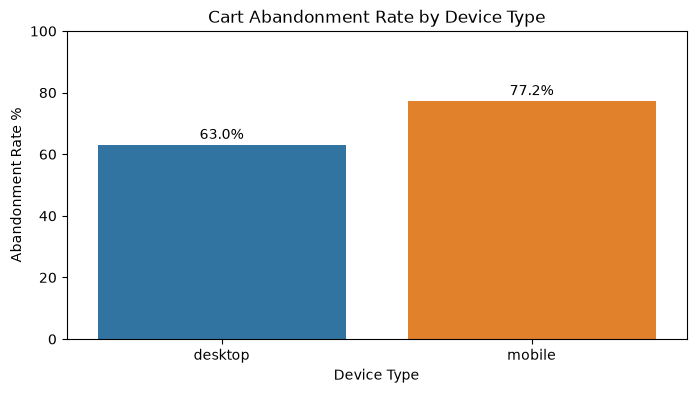

In [6]:
# Cart Abandonment by Device Type

# Calculate cart sessions and abandoned carts for each device.
device = (
    cart.groupby('device_type')
        .agg(cart_sessions=('abandoned', 'size'),
             abandoned=('abandoned', 'sum'))
        .reset_index()
)

# Calculate abandonment rate (%).
device['abandonment_rate_pct'] = (device['abandoned'] / device['cart_sessions'] * 100).round(2)

print(device)

# Visualize abandonment rates by device type.
plt.figure(figsize=(8,4))
ax = sns.barplot(data=device, x='device_type', y='abandonment_rate_pct', hue='device_type')

# Display percentage labels on bars.
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=2)

plt.title('Cart Abandonment Rate by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Abandonment Rate %')
plt.ylim(0,100)
plt.show()

             reached_cart  reached_shipping  reached_billing  completed_order
device_type                                                                  
desktop             100.0             70.11            58.18            37.00
mobile              100.0             59.56            42.11            22.77
             cart_to_shipping  shipping_to_billing  billing_to_order
device_type                                                         
desktop                 70.11                82.98             63.59
mobile                  59.56                70.69             54.08


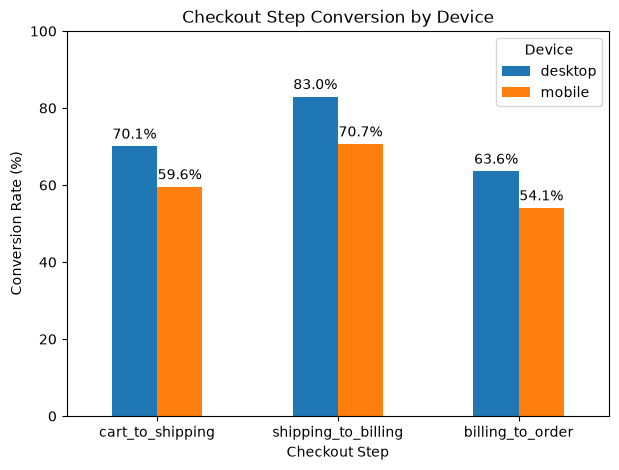

In [7]:
# Checkout Funnel Analysis by Device

# Calculate total sessions reaching each checkout stage by device.
steps = cart.groupby('device_type')[
    ['reached_cart', 'reached_shipping', 'reached_billing', 'completed_order']
].sum()

# Calculate each stage as a percentage of total cart sessions.
steps_pct = steps.div(steps['reached_cart'], axis=0).mul(100).round(2)

print(steps_pct)

# Calculate conversion rates between consecutive checkout stages.
conv = pd.DataFrame({
    'cart_to_shipping': steps['reached_shipping'] / steps['reached_cart'],
    'shipping_to_billing': steps['reached_billing'] / steps['reached_shipping'],
    'billing_to_order': steps['completed_order'] / steps['reached_billing']
}).mul(100).round(2)

print(conv)

# Visualize checkout step conversion rates by device.
ax = conv.T.plot(kind='bar', figsize=(7, 5))

# Display conversion percentages on bars.
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Checkout Step Conversion by Device')
plt.xlabel('Checkout Step')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Device')
plt.ylim(0,100)
plt.show()

      cart_sessions  abandoned  abandonment_rate_pct
hour                                                
0              2335       1538                 65.87
1              1953       1305                 66.82
2              1786       1189                 66.57
3              1548       1026                 66.28
4              1583       1011                 63.87
5              1732       1174                 67.78
6              2010       1328                 66.07
7              2484       1608                 64.73
8              3596       2360                 65.63
9              5115       3352                 65.53
10             6094       4064                 66.69
11             6310       4122                 65.32
12             6365       4181                 65.69
13             6091       4051                 66.51
14             6250       4021                 64.34
15             6272       4115                 65.61
16             6139       4069                

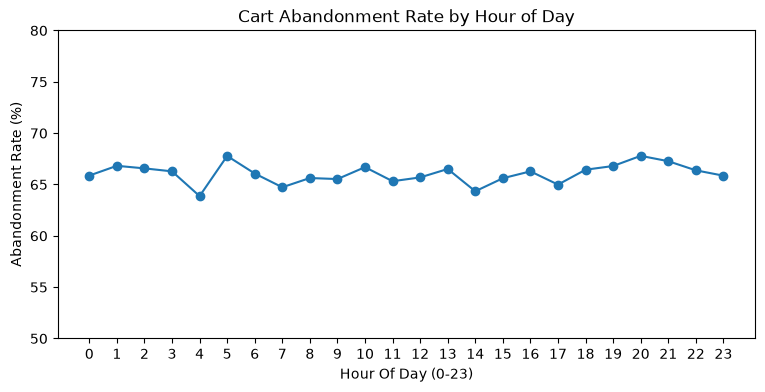

In [8]:
# Cart Abandonment by Hour

# Calculate cart sessions and abandoned carts for each hour.
hourly = cart.groupby('hour').agg(
    cart_sessions=('abandoned', 'size'),
    abandoned=('abandoned', 'sum')
)

# Calculate hourly abandonment rate (%).
hourly['abandonment_rate_pct'] = (hourly['abandoned'] / hourly['cart_sessions'] * 100).round(2)

print(hourly)

# Visualize hourly abandonment trends.
hourly['abandonment_rate_pct'].plot(kind='line', marker='o', linestyle='-', figsize=(9,4))
plt.title('Cart Abandonment Rate by Hour of Day')
plt.xlabel('Hour Of Day (0-23)')
plt.ylabel('Abandonment Rate (%)')
plt.xticks(range(0,24))
plt.ylim(50,80)
plt.show()

   is_repeat_session  cart_sessions  abandoned  abandonment_rate_pct
0                  0          76943      50779                 66.00
1                  1          18010      11861                 65.86


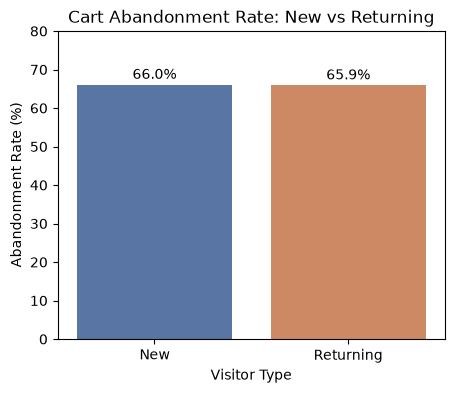

In [9]:
# Cart Abandonment: New vs Returning Visitors

# Calculate cart sessions and abandoned carts by visitor type.
repeat = cart.groupby('is_repeat_session').agg(
    cart_sessions=('abandoned', 'size'),
    abandoned=('abandoned', 'sum')
)

# Calculate abandonment rate (%) and label visitor types.
repeat['abandonment_rate_pct'] = (repeat['abandoned'] / repeat['cart_sessions'] * 100).round(2)
repeat = repeat.reset_index()

print(repeat)
repeat['visitor_type'] = repeat['is_repeat_session'].map({0: 'New', 1: 'Returning'})



# Visualize abandonment rates by visitor type.
plt.figure(figsize=(5, 4))
ax = sns.barplot(data=repeat, x='visitor_type', y='abandonment_rate_pct',
            hue='visitor_type', palette=['#4C72B0', '#DD8452'], legend=False)

# Display percentage labels on bars.
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=2)

plt.title('Cart Abandonment Rate: New vs Returning')
plt.xlabel('Visitor Type')
plt.ylabel('Abandonment Rate (%)')
plt.ylim(0,80)
plt.show()

       utm_source  cart_sessions  abandoned  abandonment_rate_pct
2         gsearch          63376      42043                 66.34
1  direct/unknown          18151      12033                 66.29
0         bsearch          12476       7957                 63.78
3      socialbook            950        607                 63.89


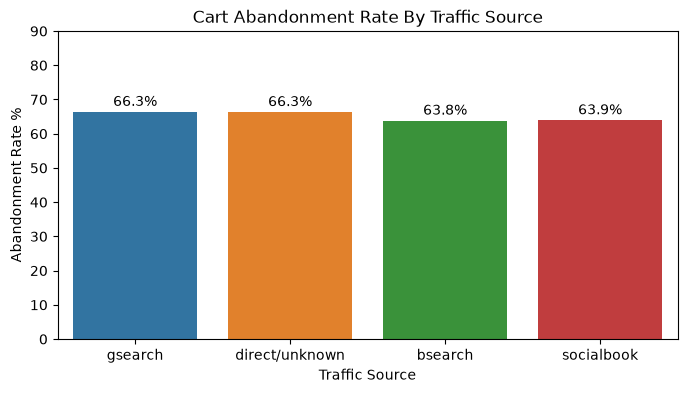

In [10]:
# Cart Abandonment by Traffic Source

# Calculate cart sessions and abandoned carts by traffic source.
source = cart.groupby('utm_source').agg(
    cart_sessions=('abandoned', 'size'),
    abandoned=('abandoned', 'sum')
).reset_index()

# Calculate abandonment rate and sort by cart session volume.
source['abandonment_rate_pct'] = (source['abandoned'] / source['cart_sessions'] * 100).round(2)
source = source.sort_values(by='cart_sessions', ascending=False)

print(source)

# Visualize abandonment rates by traffic source.
plt.figure(figsize=(8,4))
ax = sns.barplot(data=source, x='utm_source', y='abandonment_rate_pct', hue='utm_source', legend=False)

# Display percentage labels on bars.
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=2)

plt.title('Cart Abandonment Rate By Traffic Source')
plt.xlabel('Traffic Source')
plt.ylabel('Abandonment Rate %')
plt.ylim(0,90)
plt.show()

           product_before_cart  cart_sessions  abandoned  abandonment_rate_pct
3       /the-original-mr-fuzzy          69957      46096                 65.89
1       /the-forever-love-bear          14485       9682                 66.84
0    /the-birthday-sugar-panda           8811       5743                 65.18
2  /the-hudson-river-mini-bear           1700       1119                 65.82


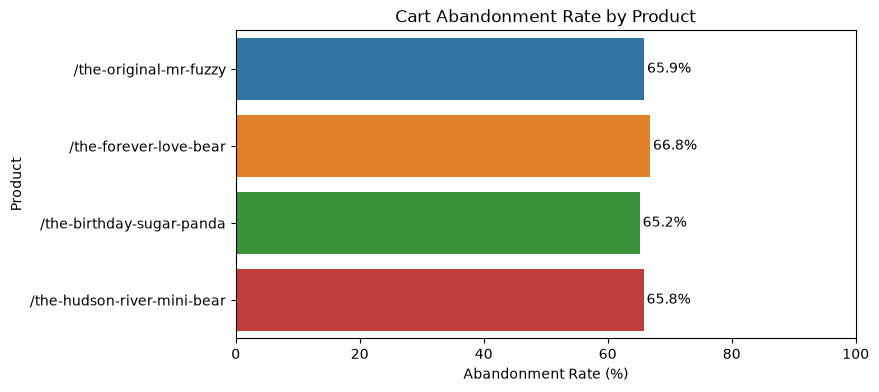

In [11]:
# Cart Abandonment by Product

# Handle missing product values.
cart['product_before_cart'] = cart['product_before_cart'].fillna('unknown')

# Calculate cart sessions and abandoned carts by product.
product = cart.groupby('product_before_cart').agg(
    cart_sessions=('abandoned', 'size'),
    abandoned=('abandoned', 'sum')
).reset_index()

# Calculate abandonment rate and sort by cart session volume.
product['abandonment_rate_pct'] = (product['abandoned'] / product['cart_sessions'] * 100).round(2)
product = product.sort_values('cart_sessions', ascending=False)

print(product)

# Visualize abandonment rates by product.
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=product, x='abandonment_rate_pct', y='product_before_cart',
                 hue='product_before_cart', legend=False)

# Display percentage labels on bars.
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=2)

plt.title('Cart Abandonment Rate by Product')
plt.xlabel('Abandonment Rate (%)')
plt.ylabel('Product')
plt.xlim(0, 100)
plt.show()

In [12]:
# Cart Abandonment by Landing Page

# Calculate cart sessions and abandoned carts by landing page.
landing = cart.groupby('landing_page').agg(
    cart_sessions=('abandoned', 'size'),
    abandoned=('abandoned', 'sum')
).reset_index()

# Calculate abandonment rate and sort by cart session volume.
landing['abandonment_rate_pct'] = (landing['abandoned'] / landing['cart_sessions'] * 100).round(2)
landing = landing.sort_values(by='cart_sessions', ascending=False)

print(landing)

  landing_page  cart_sessions  abandoned  abandonment_rate_pct
0        /home          28929      19218                 66.43
2    /lander-2          27497      17369                 63.17
5    /lander-5          18060      11130                 61.63
3    /lander-3          11494       8815                 76.69
1    /lander-1           7146       4989                 69.82
4    /lander-4           1827       1119                 61.25


In [13]:
# Landing Page Analysis by Device 

# Calculate device share (%) for each landing page.
device_share = pd.crosstab(cart['landing_page'], cart['device_type'], normalize='index').mul(100).round(1)

# Calculate abandonment rate (%) by landing page and device.
abandonment_by_device = cart.groupby(['landing_page', 'device_type'])['abandoned'].mean().mul(100).round(2).unstack()

# Identify the data collection period for each landing page.
page_period = cart.groupby('landing_page')['created_at'].agg(['min', 'max'])

# Display analysis results.
print("Device Share (%):\n", device_share)
print("\nAbandonment Rate by Device (%):\n", abandonment_by_device)
print("\nLanding Page Data Period:\n", page_period)

Device Share (%):
 device_type   desktop  mobile
landing_page                 
/home            76.7    23.3
/lander-1        88.2    11.8
/lander-2        97.4     2.6
/lander-3         0.0   100.0
/lander-4       100.0     0.0
/lander-5       100.0     0.0

Abandonment Rate by Device (%):
 device_type   desktop  mobile
landing_page                 
/home           62.94   77.92
/lander-1       68.31   81.04
/lander-2       62.86   74.83
/lander-3         NaN   76.69
/lander-4       61.25     NaN
/lander-5       61.63     NaN

Landing Page Data Period:
                              min                 max
landing_page                                        
/home        2012-03-19 09:05:46 2015-03-19 07:37:38
/lander-1    2012-06-19 10:09:29 2013-03-10 20:24:04
/lander-2    2013-01-14 00:47:15 2014-12-27 23:50:35
/lander-3    2013-07-09 08:38:32 2015-03-19 06:46:26
/lander-4    2014-02-02 07:24:23 2014-04-19 23:12:41
/lander-5    2014-08-02 00:58:50 2015-03-19 07:43:59


==== REVENUE OPPORTUNITY ANALYSIS ====

In [14]:
# Identify drop-offs at each checkout stage.
left_at_cart = (cart['reached_shipping'] == 0).sum()
left_at_shipping = ((cart['reached_shipping'] == 1) & (cart['reached_billing'] == 0)).sum()
left_at_billing = ((cart['reached_billing'] == 1) & (cart['completed_order'] == 0)).sum()

# Display drop-off counts by stage.
print("Left at Cart:", left_at_cart)
print("Left at Shipping:", left_at_shipping)
print("Left at Billing:", left_at_billing)

Left at Cart: 30469
Left at Shipping: 12426
Left at Billing: 19745


In [15]:
# Scenario A: Mobile abandonment reduced to desktop rate.
m = device.set_index('device_type')
mobile_carts = m.loc['mobile', 'cart_sessions']
desktop_rate = m.loc['desktop', 'abandonment_rate_pct'] / 100
carts_A = m.loc['mobile', 'abandoned'] - mobile_carts * desktop_rate


# Scenario B: Recover 10% of billing-stage abandoners.
carts_B = left_at_billing * 0.10

# Scenario C: Estimate recovered carts if /lander-1 matches /home performance.

# Compare abandonment rates by landing page and device.
l = cart[cart['landing_page'].isin(['/home', '/lander-1'])]
rates = l.groupby(['landing_page', 'device_type'])['abandoned'].mean().unstack()

# Get /lander-1 cart sessions by device.
l1_counts = cart[cart['landing_page'] == '/lander-1'].groupby('device_type').size()

# Estimate potential recovered carts using /home abandonment rates as benchmark.
carts_C = ((rates.loc['/lander-1'] - rates.loc['/home']) * l1_counts).sum()

# Display estimated recovered orders.
print("Scenario A - Potentially Recovered Carts:", carts_A)
print("Scenario B - Potentially Recovered Carts:", carts_B)
print("Scenario C - Potentially Recovered Carts:", carts_C)

Scenario A - Potentially Recovered Carts: 2817.26
Scenario B - Potentially Recovered Carts: 1974.5
Scenario C - Potentially Recovered Carts: 365.01253592502303


                    scenario  carts_recovered  revenue_usd
0     Mobile at desktop rate           2817.0     169012.0
1  10% of billing abandoners           1974.0     118453.0
2    /lander-1 at /home rate            365.0      21898.0


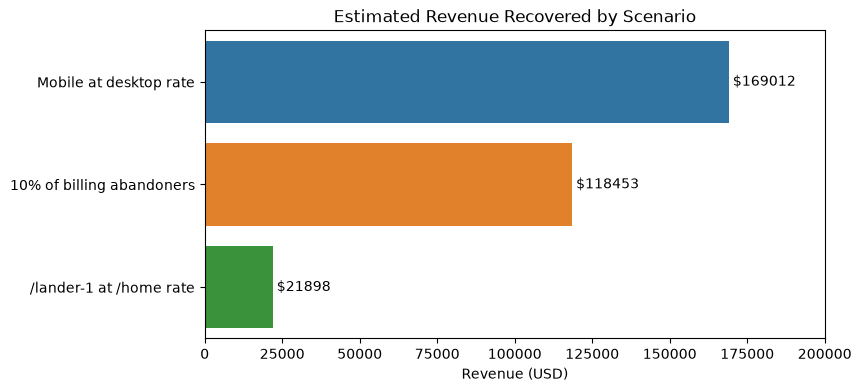

In [16]:
# Opportunity Analysis: Estimated Cart Recovery & Revenue

# Compare potential cart recovery across all three scenarios.
opp = pd.DataFrame({
    'scenario': ['Mobile at desktop rate', '10% of billing abandoners', '/lander-1 at /home rate'],
    'carts_recovered': [carts_A, carts_B, carts_C]
})

# Estimate recovered revenue using Average Order Value (AOV).
opp['revenue_usd'] = (opp['carts_recovered'] * aov).round(0)
opp['carts_recovered'] = opp['carts_recovered'].round(0)

print(opp)

# Visualize estimated revenue recovery by scenario.
plt.figure(figsize=(8,4))
ax = sns.barplot(data=opp, x='revenue_usd', y='scenario',
                 hue='scenario', legend=False)

# Display revenue labels on bars.
for container in ax.containers:
    ax.bar_label(container, fmt='$%.0f', padding=3)

plt.title('Estimated Revenue Recovered by Scenario')
plt.xlabel('Revenue (USD)')
plt.ylabel('')
plt.xlim(0,200000)
plt.show()